# Entrega 2 — CNN treinada do zero

**Autor:** Matheus Fontes — RM 570457.

**Grupo 21:** Lucas Carvalho Cordeiro — RM 570388; Larissa da Silva Marcelino — RM 571790; Elton Modesto de Souza Dias — RM 572530; Matheus Fontes — RM 570457. **Tutora:** Nicolly Candida.

Nova execução na base v2 corrigida, com arquitetura e hiperparâmetros da contribuição original. A orientação EXIF é aplicada na cópia local para que a CNN veja a mesma orientação usada pela YOLO. A rede aprende a classe da foto inteira; não localiza objetos.

In [1]:
import os, sys, subprocess, importlib.util
for modulo,pacote in [('tensorflow','tensorflow'),('sklearn','scikit-learn'),('yaml','PyYAML'),('PIL','Pillow')]:
    if importlib.util.find_spec(modulo) is None:subprocess.run([sys.executable,'-m','pip','install',pacote],check=True)
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
os.environ['OMP_NUM_THREADS']='4'
import time, random, platform, shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers,models
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay
from IPython.display import display
import pandas as pd
from PIL import Image,ImageOps
# Limita o uso de CPU no ambiente compartilhado e registra as versões.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
IMG_SIZE=(128,128);BATCH_SIZE=8;EPOCHS=30;SEED=42
random.seed(SEED);np.random.seed(SEED);tf.random.set_seed(SEED)
print('Python:',platform.python_version(),'TensorFlow:',tf.__version__)
print('GPUs:',tf.config.list_physical_devices('GPU'))


I0000 00:00:1791858757.564859  260350 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791858758.585274  260350 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: 3.12.3 TensorFlow: 2.21.0
GPUs: []


## 1. Mesma base e mesmas oito fotos de teste

In [2]:
from pathlib import Path
import os, json, csv, hashlib, zipfile
from urllib.request import urlopen
import yaml

BASE_VERSAO = 'base_v2_sem_duplicatas'
URL_BASE = 'https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/releases/download/base-v2/dataset_farmtech_grupo21_v2.zip'
SHA_ZIP = '120aeffbf4c78e27e69565a5a08bddff73e200dbf38e7acadc685e98b92deb2d'
RAIZ_EXECUCAO = Path('/content') if Path('/content').is_dir() else Path.cwd()
# No Colab, o enunciado pede conexão ao Drive. A pasta v2 pertence ao usuário
# que montar o Drive; não precisamos escrever na pasta compartilhada antiga.
try:
    from google.colab import drive
except ImportError:
    EM_COLAB = False
else:
    EM_COLAB = True
    drive.mount('/content/drive')
RAIZ_ARQUIVOS = Path('/content/drive/MyDrive/FIAP_fase6_grupo21_base_v2') if EM_COLAB else RAIZ_EXECUCAO
RAIZ_ARQUIVOS.mkdir(parents=True, exist_ok=True)
RESULTADOS_PADRAO = RAIZ_ARQUIVOS / 'resultados_farmtech_v2'
BASE = Path(os.environ.get('FARMTECH_DATASET_ROOT', str(RAIZ_ARQUIVOS / 'dataset_yolo/organizado')))

if not (BASE / 'manifesto.csv').is_file():
    BASE.mkdir(parents=True, exist_ok=True)
    pacote = RAIZ_EXECUCAO / 'dataset_farmtech_grupo21_v2.zip'
    print('Baixando a base corrigida, com 80 imagens e suas marcações...')
    with urlopen(URL_BASE, timeout=120) as resposta:
        pacote.write_bytes(resposta.read())
    assert hashlib.sha256(pacote.read_bytes()).hexdigest() == SHA_ZIP, 'ZIP diferente da base publicada.'
    with zipfile.ZipFile(pacote) as z:
        assert all((BASE / f.filename).resolve().is_relative_to(BASE.resolve()) for f in z.infolist())
        z.extractall(BASE)

manifesto = list(csv.DictReader((BASE / 'manifesto.csv').open(newline='')))
assert len(manifesto) == 80
assert len({r['sha256_imagem'] for r in manifesto}) == 80
for r in manifesto:
    imagem = BASE / 'images' / r['conjunto'] / r['arquivo']
    marcacao = BASE / 'labels' / r['conjunto'] / r['marcacao']
    assert hashlib.sha256(imagem.read_bytes()).hexdigest() == r['sha256_imagem'], imagem.name
    linhas = marcacao.read_text().strip().splitlines()
    assert len(linhas) == int(r['quantidade_caixas'])
    for linha in linhas:
        classe, x, y, w, h = map(float, linha.split())
        assert int(classe) == int(r['classe_id']) and 0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1
for conjunto, n in [('train', 32), ('val', 4), ('test', 4)]:
    for classe in [0, 1]:
        assert sum(r['conjunto'] == conjunto and int(r['classe_id']) == classe for r in manifesto) == n
print('Base v2 conferida: 64 treino, 8 validação, 8 teste; 32/4/4 por classe. Imagens verificadas por SHA-256.')
print('Base local:', BASE)


Base v2 conferida: 64 treino, 8 validação, 8 teste; 32/4/4 por classe. Imagens verificadas por SHA-256.
Base local: /tmp/farmtech_base_v2/organizado


## 2. Cópia local por classe e orientação correta

A cópia aplica EXIF antes da leitura pelo TensorFlow. Não altera as fotos originais nem o manifesto. Fotos podem conter várias bananas; há uma classe alvo por foto.

In [3]:
from collections import Counter
DATASET_DIR=Path(os.environ.get('FARMTECH_CNN_COPY',str(RAIZ_EXECUCAO/'cnn_dataset_v2')))
DATASET_DIR.mkdir(parents=True,exist_ok=True)
contagem=Counter()
for r in manifesto:
    dest=DATASET_DIR/r['conjunto']/r['classe']/r['arquivo']
    dest.parent.mkdir(parents=True,exist_ok=True)
    with Image.open(BASE/'images'/r['conjunto']/r['arquivo']) as im:
        ImageOps.exif_transpose(im).convert('RGB').save(dest,quality=95)
    contagem[(r['conjunto'],r['classe'])]+=1
for k,n in sorted(contagem.items()):print(k,n)
assert sum(contagem.values())==80
OUTPUT_DIR=Path(os.environ.get('FARMTECH_OUTPUT_ROOT',str(RESULTADOS_PADRAO)))/'cnn'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)


('test', 'banana') 4
('test', 'garrafa_pet') 4
('train', 'banana') 32
('train', 'garrafa_pet') 32
('val', 'banana') 4
('val', 'garrafa_pet') 4


## 3. Leitura das imagens — 128 × 128

In [4]:
train_ds=tf.keras.utils.image_dataset_from_directory(DATASET_DIR/'train',image_size=IMG_SIZE,batch_size=BATCH_SIZE,shuffle=True,seed=SEED)
val_ds=tf.keras.utils.image_dataset_from_directory(DATASET_DIR/'val',image_size=IMG_SIZE,batch_size=BATCH_SIZE,shuffle=False)
test_ds=tf.keras.utils.image_dataset_from_directory(DATASET_DIR/'test',image_size=IMG_SIZE,batch_size=BATCH_SIZE,shuffle=False)
class_names=train_ds.class_names
test_paths=list(test_ds.file_paths)
options=tf.data.Options();options.threading.private_threadpool_size=2
train_ds=train_ds.with_options(options).prefetch(1)
val_ds=val_ds.with_options(options).prefetch(1)
test_ds=test_ds.with_options(options).prefetch(1)
assert class_names==['banana','garrafa_pet']
print('Classes:',class_names)


Found 64 files belonging to 2 classes.


Found 8 files belonging to 2 classes.


Found 8 files belonging to 2 classes.


Classes: ['banana', 'garrafa_pet']


## 4. Arquitetura original, pesos aleatórios

Flip horizontal, rotação e zoom no treino; três convoluções com 16/32/64 filtros; camada densa de 64; dropout 0,5 e sigmoid. Adam, entropia cruzada binária, 30 épocas, lote 8 e seed 42. Não usamos MobileNet nem pesos ImageNet.

In [5]:
data_augmentation=models.Sequential([layers.RandomFlip('horizontal'),layers.RandomRotation(0.1),layers.RandomZoom(0.1)])
model=models.Sequential([layers.Input(shape=IMG_SIZE+(3,)),data_augmentation,layers.Rescaling(1./255),layers.Conv2D(16,3,activation='relu'),layers.MaxPooling2D(),layers.Conv2D(32,3,activation='relu'),layers.MaxPooling2D(),layers.Conv2D(64,3,activation='relu'),layers.MaxPooling2D(),layers.Flatten(),layers.Dense(64,activation='relu'),layers.Dropout(0.5),layers.Dense(1,activation='sigmoid')])
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
assert model.count_params()==826529
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 826,529 (3.15 MB)

 Trainable params: 826,529 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Treinamento

In [6]:
t0=time.perf_counter()
history=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,verbose=2)
train_time=time.perf_counter()-t0
print(f'Tempo de treinamento: {train_time:.3f} segundos')
pd.DataFrame(history.history).assign(epoch=range(1,EPOCHS+1)).to_csv(OUTPUT_DIR/'historico_treinamento.csv',index=False)
model.save(OUTPUT_DIR/'cnn_base_v2.keras')


Epoch 1/30


/tmp/farmtech_yolo_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 - 2s - 263ms/step - accuracy: 0.3906 - loss: 0.7964 - val_accuracy: 0.5000 - val_loss: 0.6779


Epoch 2/30


8/8 - 2s - 188ms/step - accuracy: 0.4062 - loss: 0.7044 - val_accuracy: 0.5000 - val_loss: 0.6758


...

Epoch 29/30


8/8 - 1s - 88ms/step - accuracy: 1.0000 - loss: 0.0142 - val_accuracy: 1.0000 - val_loss: 0.0293


Epoch 30/30


8/8 - 1s - 87ms/step - accuracy: 0.9844 - loss: 0.0496 - val_accuracy: 1.0000 - val_loss: 0.0348


Tempo de treinamento: 21.441 segundos


## 6. Curvas de treino e validação

/tmp/ipykernel_260350/3406791460.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout();fig.savefig(OUTPUT_DIR/'curvas_cnn.png',dpi=120);plt.show()


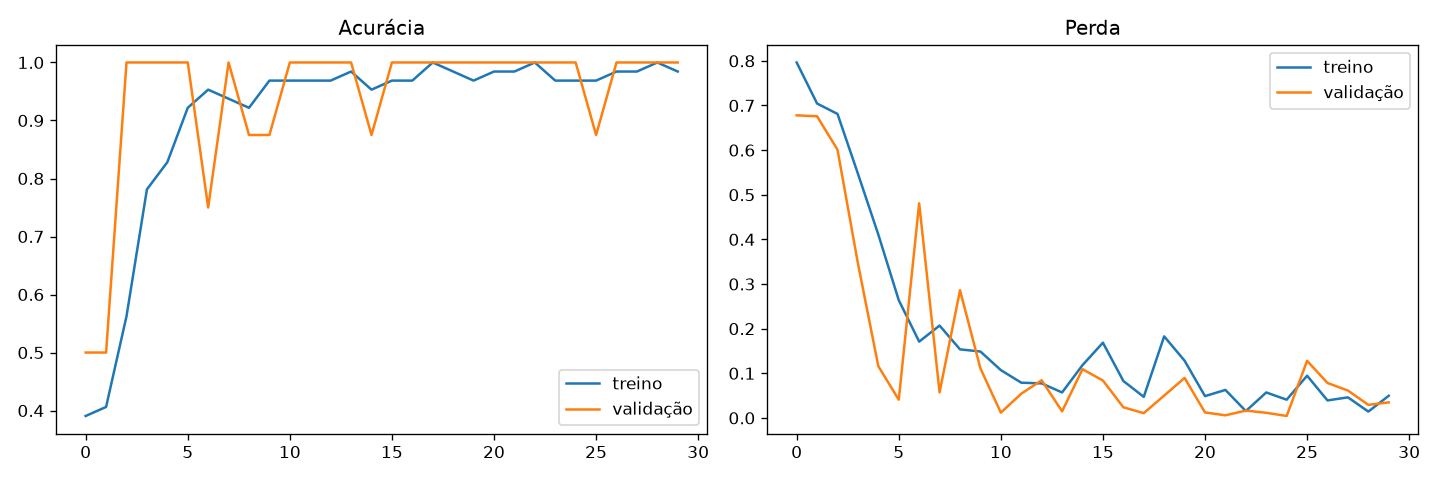

In [7]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(history.history['accuracy'],label='treino');ax[0].plot(history.history['val_accuracy'],label='validação');ax[0].set_title('Acurácia');ax[0].legend()
ax[1].plot(history.history['loss'],label='treino');ax[1].plot(history.history['val_loss'],label='validação');ax[1].set_title('Perda');ax[1].legend()
fig.tight_layout();fig.savefig(OUTPUT_DIR/'curvas_cnn.png',dpi=120);plt.show()


## 7. Teste reservado e matriz de confusão

Sigmoid é a probabilidade de garrafa PET. Valores abaixo de 0,5 indicam banana. A confiança da classe prevista é `p` para PET e `1-p` para banana.

Teste: 8/8 | acurácia=1.0000 | perda=0.001918
              precision    recall  f1-score   support

      banana       1.00      1.00      1.00         4
 garrafa_pet       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



/tmp/ipykernel_260350/1005197636.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  cm=confusion_matrix(y_true,y_pred,labels=[0,1]);disp=ConfusionMatrixDisplay(cm,display_labels=class_names);disp.plot();plt.tight_layout();plt.savefig(OUTPUT_DIR/'matriz_confusao_cnn.png',dpi=120);plt.show()


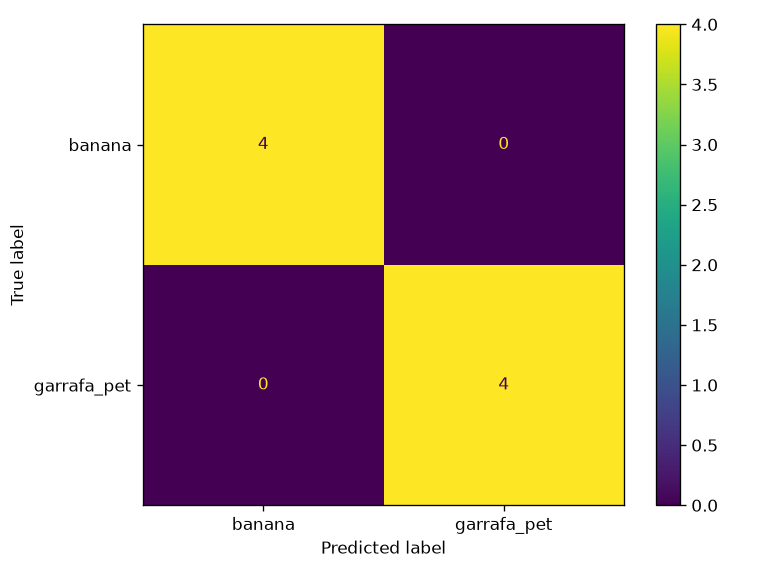

,arquivo,classe_real,predicao_cnn,probabilidade_pet,confianca_classe_prevista,acertou,sha256_imagem
0,20261011_220831.jpg,banana,banana,1.309822e-04,0.999869,True,94e4fae57f70a3e6cf7793e53cfd35117e9297447aa5e6...
1,20261011_221012.jpg,banana,banana,1.488490e-07,1.000000,True,7a92277952f6c3696e7479612b5d5ddbe30b69d9315a8a...
2,IMG-20261005-WA0006.jpg,banana,banana,6.493678e-03,0.993506,True,e915f8e8312a470324a3b29c4e21e91e1f19f7edb2b874...
3,IMG-20261005-WA0008.jpg,banana,banana,1.370348e-04,0.999863,True,da6926d3062f0bbb7e1e11f3aaa9a83265b2bc3b33e5f5...
4,20261009_191256.jpg,garrafa_pet,garrafa_pet,9.999997e-01,1.000000,True,9937ada70178bc731201993af79996e1b748deb3b1cb5d...
5,IMG-20261005-WA0044.jpg,garrafa_pet,garrafa_pet,9.997724e-01,0.999772,True,3b028f57e6ffc49be78511ee951fec1807cc32a8840674...
6,IMG-20261005-WA0060.jpg,garrafa_pet,garrafa_pet,9.918545e-01,0.991854,True,38a73d472f49ecad34ebe1835857e88c6e31f4382f8fb2...
7,IMG-20261005-WA0112.jpg,garrafa_pet,garrafa_pet,9.998488e-01,0.999849,True,3afde1b734b9decb9e8fb29fad3aeae6c4eddd90e6ea09...


In [8]:
test_loss,test_acc=model.evaluate(test_ds,verbose=0)
y_true=np.concatenate([y.numpy() for _,y in test_ds]).astype(int)
y_prob=model.predict(test_ds,verbose=0).ravel();y_pred=(y_prob>0.5).astype(int)
print(f'Teste: {int((y_true==y_pred).sum())}/8 | acurácia={test_acc:.4f} | perda={test_loss:.6f}')
print(classification_report(y_true,y_pred,target_names=class_names,zero_division=0))
cm=confusion_matrix(y_true,y_pred,labels=[0,1]);disp=ConfusionMatrixDisplay(cm,display_labels=class_names);disp.plot();plt.tight_layout();plt.savefig(OUTPUT_DIR/'matriz_confusao_cnn.png',dpi=120);plt.show()
linhas=[]
for p,real,pred,prob in zip(test_paths,y_true,y_pred,y_prob):
    nome=Path(p).name;original=BASE/'images/test'/nome
    linhas.append({'arquivo':nome,'classe_real':class_names[real],'predicao_cnn':class_names[pred],'probabilidade_pet':float(prob),'confianca_classe_prevista':float(prob if pred==1 else 1-prob),'acertou':bool(pred==real),'sha256_imagem':hashlib.sha256(original.read_bytes()).hexdigest()})
predicoes_cnn=pd.DataFrame(linhas);predicoes_cnn.to_csv(OUTPUT_DIR/'predicoes_cnn.csv',index=False);display(predicoes_cnn)


## 8. Galeria das oito imagens classificadas

/tmp/ipykernel_260350/3898860412.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout();fig.savefig(OUTPUT_DIR/'galeria_teste_cnn.png',dpi=120);plt.show()


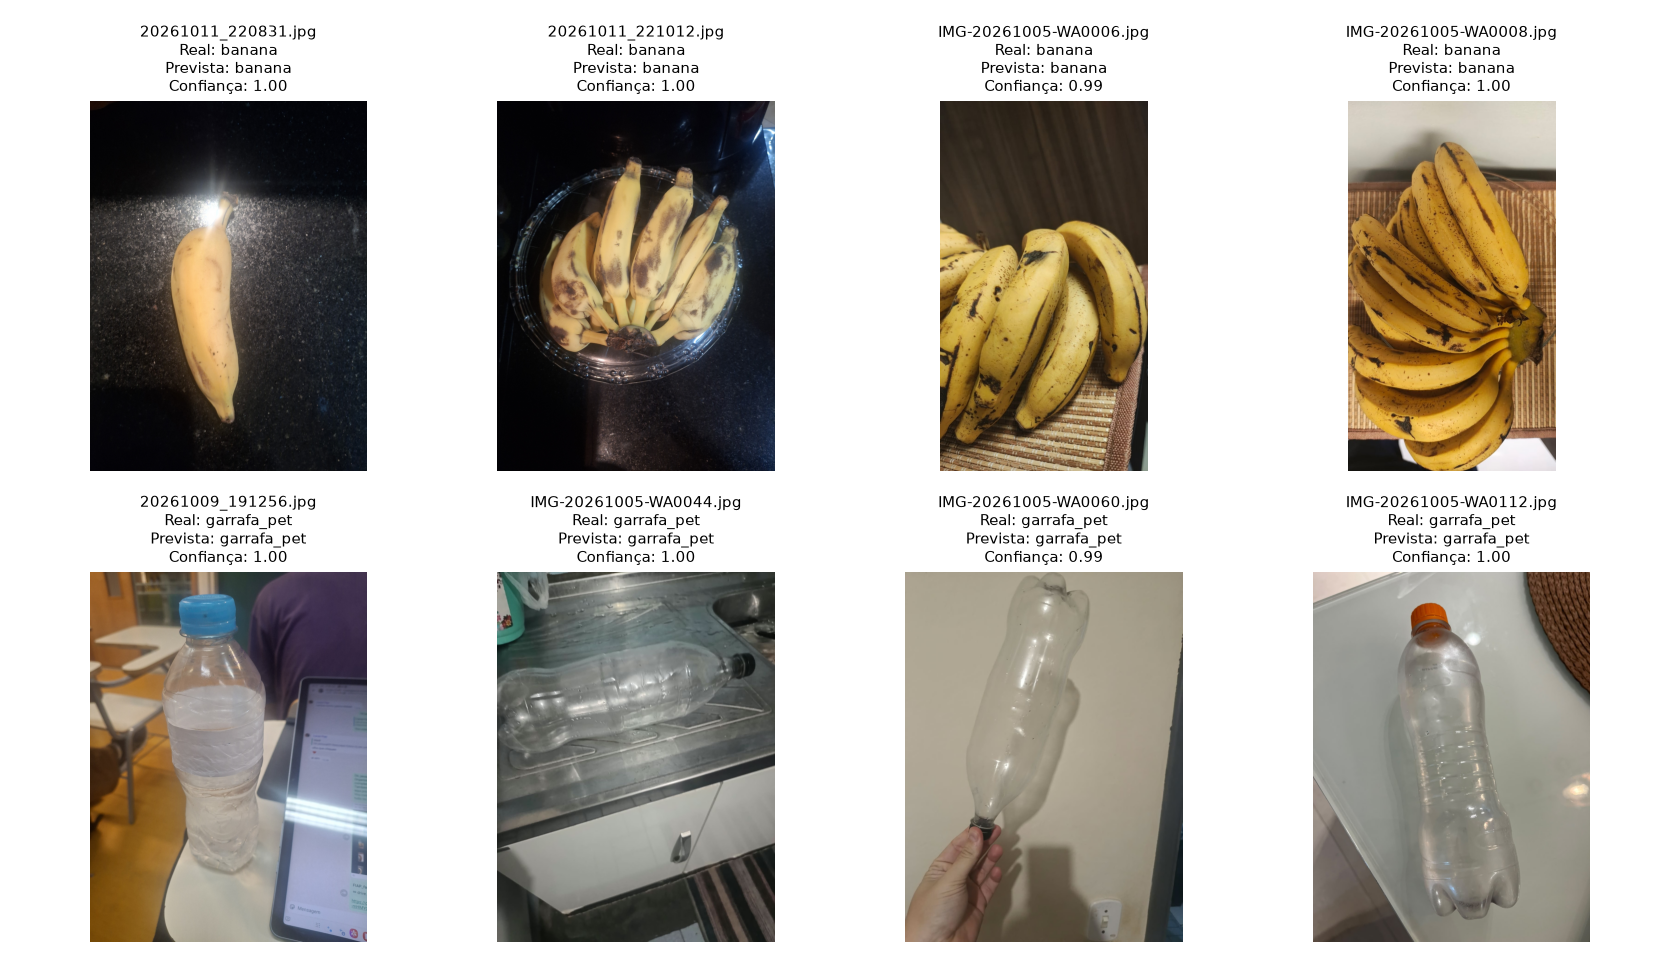

In [9]:
fig,axes=plt.subplots(2,4,figsize=(14,8))
for ax,p,linha in zip(axes.flat,test_paths,linhas):
    ax.imshow(Image.open(p));ax.set_title(f"{linha['arquivo']}\nReal: {linha['classe_real']}\nPrevista: {linha['predicao_cnn']}\nConfiança: {linha['confianca_classe_prevista']:.2f}",fontsize=9);ax.axis('off')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'galeria_teste_cnn.png',dpi=120);plt.show()


## 9. Tempo, ambiente e resultado para comparação

Uma chamada de aquecimento fica fora. Medimos `predict` sobre oito fotos em lote, incluindo o pipeline, e dividimos por oito. Não é diretamente o tempo isolado da rede YOLO. Igualar épocas não controla diferenças entre arquiteturas e resoluções.

In [10]:
model.predict(test_ds,verbose=0)
t0=time.perf_counter();model.predict(test_ds,verbose=0);infer_time=(time.perf_counter()-t0)/8
hardware=next((s.split(':',1)[1].strip() for s in open('/proc/cpuinfo') if s.startswith('model name')),platform.processor() or 'CPU') if os.path.isfile('/proc/cpuinfo') else platform.processor() or 'CPU'
ambiente={'python':platform.python_version(),'tensorflow':tf.__version__,'keras':tf.keras.__version__,'hardware':hardware,'dispositivo':'GPU' if tf.config.list_physical_devices('GPU') else 'CPU','entrada':[128,128],'batch_size':8,'epocas':30,'seed':42,'parametros':model.count_params(),'orientacao_exif':True,'base_versao':BASE_VERSAO,'sha256_manifesto':hashlib.sha256((BASE/'manifesto.csv').read_bytes()).hexdigest()}
resumo={'base_versao':BASE_VERSAO,'acertos':int((y_true==y_pred).sum()),'fotos_teste':8,'acuracia':float(test_acc),'perda_teste':float(test_loss),'matriz_confusao':cm.tolist(),'tempo_treinamento_s':train_time,'tempo_inferencia_ms_por_foto':infer_time*1000,'epocas':30,'hardware':hardware,'entrada':'128 x 128','batch_size':8,'escopo_tempo':'predict no conjunto de teste após aquecimento; lote 8, média por imagem incluindo o pipeline','ambiente':ambiente,'modelo_sha256':hashlib.sha256((OUTPUT_DIR/'cnn_base_v2.keras').read_bytes()).hexdigest()}
(OUTPUT_DIR/'resultado_cnn.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2))
(OUTPUT_DIR/'ambiente_execucao.json').write_text(json.dumps(ambiente,ensure_ascii=False,indent=2))
print(json.dumps(resumo,ensure_ascii=False,indent=2))


{
  "base_versao": "base_v2_sem_duplicatas",
  "acertos": 8,
  "fotos_teste": 8,
  "acuracia": 1.0,
  "perda_teste": 0.0019176312489435077,
  "matriz_confusao": [
    [
      4,
      0
    ],
    [
      0,
      4
    ]
  ],
  "tempo_treinamento_s": 21.440830156992888,
  "tempo_inferencia_ms_por_foto": 13.42050787206972,
  "epocas": 30,
  "hardware": "Intel(R) Core(TM) 7 150U",
  "entrada": "128 x 128",
  "batch_size": 8,
  "escopo_tempo": "predict no conjunto de teste após aquecimento; lote 8, média por imagem incluindo o pipeline",
  "ambiente": {
    "python": "3.12.3",
    "tensorflow": "2.21.0",
    "keras": "3.15.1",
    "hardware": "Intel(R) Core(TM) 7 150U",
    "dispositivo": "CPU",
    "entrada": [
      128,
      128
    ],
    "batch_size": 8,
    "epocas": 30,
    "seed": 42,
    "parametros": 826529,
    "orientacao_exif": true,
    "base_versao": "base_v2_sem_duplicatas",
    "sha256_manifesto": "a1e2b05d9dccde76b97a04ceee1f983ca7ad987ab0b795e6171eb281227225ba"
  },
 

## 10. Conclusão

A CNN foi treinada novamente, do zero, por **30 épocas**, com **826.529 parâmetros**, e acertou **8/8 fotos de teste (100,00%)**. O treinamento levou **21,44 s** e o `predict`, medido após aquecimento sobre oito fotos em lote, levou **13,42 ms por foto**.

As imagens receberam a orientação EXIF correta na cópia local. A arquitetura e os hiperparâmetros da contribuição original foram mantidos, e os resultados atuais são da base v2. A rede classifica a foto inteira; não localiza objetos. Mesmo um resultado de 8/8 não prova generalização: o teste é pequeno e há cenários semelhantes entre fotos. A conclusão é restrita a este conjunto.